# 🧠 Semantic Segmentation with ENet — Custom Roboflow Dataset

Notebook ini melatih model **ENet** untuk semantic segmentation menggunakan dataset custom dari Roboflow dalam format PNG mask.

**Arsitektur:** ENet (Efficient Neural Network) — ringan, cepat, cocok untuk real-time segmentation  
**Referensi:** [yassouali/pytorch-segmentation](https://github.com/yassouali/pytorch-segmentation/blob/master/models/enet.py)

---

**Alur Notebook:**
1. Konfigurasi & Path
2. Install Libraries
3. Ekstrak & Persiapan Dataset
4. Arsitektur ENet
5. Dataset Class & Augmentasi
6. Data Collator & Metrics (mIoU)
7. Training & Checkpoint Management
8. Evaluasi & Visualisasi
9. Zip & Export Model

In [1]:
import os
import re
import zipfile
import shutil
import random
import numpy as np
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import cv2

print(f"PyTorch version  : {torch.__version__}")
print(f"CUDA available   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU              : {torch.cuda.get_device_name(0)}")

# ==========================================
# 1. KAGGLE CONFIGURATION & PATHS
# ==========================================

# ⚠️  SESUAIKAN: Ganti nama file zip sesuai nama file yang kamu upload ke Kaggle
ZIP_PATH = "/kaggle/input/your-dataset/your-dataset.zip"  # <-- GANTI INI

# ⚠️  SESUAIKAN: Jumlah kelas termasuk background (misal: background + 2 objek = 3)
NUM_CLASSES = 4   # <-- GANTI INI

# ⚠️  SESUAIKAN: Nama setiap kelas (urut sesuai nilai pixel di mask)
CLASS_NAMES = ["background", "drivable_area", "pothole", "speed_bump"]  # <-- GANTI INI

# ⚠️  SESUAIKAN: Resolusi input (harus habis dibagi 8 untuk ENet, misal 256, 512, 640)
IMG_HEIGHT = 256   # <-- GANTI INI
IMG_WIDTH  = 512   # <-- GANTI INI


# Working Paths
DATA_DIR          = "/kaggle/input/datasets/ryosukeeh/v-lapan"
TRAIN_IMG_DIR     = "/kaggle/input/datasets/ryosukeeh/v-lapan/train/images"
TRAIN_MASK_DIR    = "/kaggle/input/datasets/ryosukeeh/v-lapan/train/masks"
VAL_IMG_DIR       = "/kaggle/input/datasets/ryosukeeh/v-lapan/valid/images"
VAL_MASK_DIR      = "/kaggle/input/datasets/ryosukeeh/v-lapan/valid/masks"
MODEL_OUTPUT_DIR  = "/kaggle/working/ENet_Model_DRVA_vLapan"

# Jika kamu ingin resume dari checkpoint sebelumnya, isi path-nya di sini
PREVIOUS_CHECKPOINT = None  # Contoh: "/kaggle/input/notebooks/ENet_Model/checkpoint_epoch10.pth"

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

print("\nKonfigurasi selesai!")
print(f"  NUM_CLASSES : {NUM_CLASSES}")
print(f"  Input size  : {IMG_HEIGHT}x{IMG_WIDTH}")
print(f"  Output dir  : {MODEL_OUTPUT_DIR}")

PyTorch version  : 2.10.0+cu128
CUDA available   : True
GPU              : Tesla T4

Konfigurasi selesai!
  NUM_CLASSES : 4
  Input size  : 256x512
  Output dir  : /kaggle/working/ENet_Model_DRVA_vLapan


In [2]:
# ==========================================
# 2. INSTALL LIBRARIES
# ==========================================
# albumentations  : augmentasi gambar yang kuat & cepat
# segmentation-models-pytorch : helper metrics

!pip install -q albumentations

import albumentations as A
from albumentations.pytorch import ToTensorV2

print("Libraries siap!")

Libraries siap!


In [3]:
# ==========================================
# 3. EKSTRAK & PERSIAPAN DATASET
# ==========================================
# Format dataset Roboflow (PNG mask) yang diharapkan setelah ekstrak:
#
#   dataset/
#   ├── train/
#   │   ├── images/   ← file .jpg / .png gambar asli
#   │   └── masks/    ← file .png mask (grayscale, nilai pixel = class index)
#   └── valid/
#       ├── images/
#       └── masks/
#
# Jika struktur foldermu berbeda, sesuaikan bagian di bawah ini.

# print("\n--- Mengekstrak Dataset ---")

# if not os.path.exists(DATA_DIR):
#     os.makedirs(DATA_DIR, exist_ok=True)
#     with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
#         zf.extractall(DATA_DIR)
#     print(f"Ekstraksi selesai ke {DATA_DIR}")
# else:
#     print(f"Dataset sudah ada di {DATA_DIR}, skip ekstraksi.")

# Verifikasi struktur
for split in ['train', 'valid']:
    img_dir  = f"{DATA_DIR}/{split}/images"
    msk_dir  = f"{DATA_DIR}/{split}/masks"
    if os.path.exists(img_dir):
        imgs  = len(os.listdir(img_dir))
        masks = len(os.listdir(msk_dir)) if os.path.exists(msk_dir) else 0
        print(f"  [{split}] images: {imgs} | masks: {masks}")
    else:
        print(f"  ⚠️  Folder {img_dir} tidak ditemukan. Periksa struktur ZIP.")

  [train] images: 1023 | masks: 1023
  [valid] images: 123 | masks: 123


In [4]:
# ==========================================
# 4. ARSITEKTUR ENET
# ==========================================
# Diadaptasi langsung dari:
# https://github.com/yassouali/pytorch-segmentation/blob/master/models/enet.py

def initialize_weights(*models):
    """Inisialisasi bobot kaiming untuk Conv2d dan BatchNorm."""
    for model in models:
        for module in model.modules():
            if isinstance(module, nn.Conv2d) or isinstance(module, nn.ConvTranspose2d):
                nn.init.kaiming_normal_(module.weight)
                if module.bias is not None:
                    module.bias.data.zero_()
            elif isinstance(module, nn.BatchNorm2d):
                module.weight.data.fill_(1)
                module.bias.data.zero_()


class InitialBlock(nn.Module):
    """Blok pertama ENet: menggabungkan MaxPool dan Conv untuk efisiensi."""
    def __init__(self, in_channels, use_prelu=True):
        super(InitialBlock, self).__init__()
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2, ceil_mode=True)
        self.conv  = nn.Conv2d(in_channels, 16 - in_channels, 3, padding=1, stride=2)
        self.bn    = nn.BatchNorm2d(16)
        self.prelu = nn.PReLU(16) if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x):
        x = torch.cat((self.pool(x), self.conv(x)), dim=1)
        x = self.bn(x)
        x = self.prelu(x)
        return x


class BottleNeck(nn.Module):
    """
    Bottleneck ENet yang mendukung:
    - Regular convolution
    - Dilated convolution
    - Asymmetric convolution (1x5 + 5x1)
    - Downsampling (MaxPool + strided conv)
    - Upsampling (MaxUnpool + transposed conv)
    """
    def __init__(self, in_channels, out_channels=None, dilation=1, downsample=False,
                 proj_ratio=4, upsample=False, asymetric=False,
                 regularize=True, p_drop=None, use_prelu=True):
        super(BottleNeck, self).__init__()
        self.pad        = 0
        self.upsample   = upsample
        self.downsample = downsample

        if out_channels is None:
            out_channels = in_channels
        else:
            self.pad = out_channels - in_channels

        if regularize: assert p_drop is not None
        if downsample: assert not upsample
        elif upsample: assert not downsample

        inter_channels = in_channels // proj_ratio

        # ---- Main branch (identity / pool / unpool) ----
        if upsample:
            self.spatil_conv = nn.Conv2d(in_channels, out_channels, 1, bias=False)
            self.bn_up       = nn.BatchNorm2d(out_channels)
            self.unpool      = nn.MaxUnpool2d(kernel_size=2, stride=2)
        elif downsample:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True)

        # ---- Bottleneck branch ----
        # 1x1 projection
        self.conv1  = nn.Conv2d(in_channels, inter_channels, 2 if downsample else 1,
                                stride=2 if downsample else 1, bias=False)
        self.bn1    = nn.BatchNorm2d(inter_channels)
        self.prelu1 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        # main conv
        if asymetric:
            self.conv2 = nn.Sequential(
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(1, 5), padding=(0, 2)),
                nn.BatchNorm2d(inter_channels),
                nn.PReLU() if use_prelu else nn.ReLU(inplace=True),
                nn.Conv2d(inter_channels, inter_channels, kernel_size=(5, 1), padding=(2, 0)),
            )
        elif upsample:
            self.conv2 = nn.ConvTranspose2d(inter_channels, inter_channels,
                                            kernel_size=3, padding=1,
                                            output_padding=1, stride=2, bias=False)
        else:
            self.conv2 = nn.Conv2d(inter_channels, inter_channels, 3,
                                   padding=dilation, dilation=dilation, bias=False)

        self.bn2    = nn.BatchNorm2d(inter_channels)
        self.prelu2 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        # 1x1 expansion
        self.conv3  = nn.Conv2d(inter_channels, out_channels, 1, bias=False)
        self.bn3    = nn.BatchNorm2d(out_channels)
        self.prelu3 = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

        self.regularizer = nn.Dropout2d(p_drop) if regularize else None
        self.prelu_out   = nn.PReLU() if use_prelu else nn.ReLU(inplace=True)

    def forward(self, x, indices=None, output_size=None):
        identity = x

        if self.upsample:
            assert (indices is not None) and (output_size is not None)
            identity = self.bn_up(self.spatil_conv(identity))
            if identity.size() != indices.size():
                pad = (indices.size(3) - identity.size(3), 0,
                       indices.size(2) - identity.size(2), 0)
                identity = F.pad(identity, pad, "constant", 0)
            identity = self.unpool(identity, indices=indices)
        elif self.downsample:
            identity, idx = self.pool(identity)
            if self.pad > 0:
                extras   = torch.zeros((identity.size(0), self.pad,
                                        identity.size(2), identity.size(3)),
                                       device=x.device)
                identity = torch.cat((identity, extras), dim=1)

        # Bottleneck
        x = self.prelu1(self.bn1(self.conv1(x)))
        x = self.conv2(x)
        x = self.prelu2(self.bn2(x))
        x = self.prelu3(self.bn3(self.conv3(x)))

        if self.regularizer is not None:
            x = self.regularizer(x)

        # Align spatial size jika ada perbedaan 1 pixel
        if identity.size() != x.size():
            pad = (identity.size(3) - x.size(3), 0,
                   identity.size(2) - x.size(2), 0)
            x = F.pad(x, pad, "constant", 0)

        x = self.prelu_out(x + identity)

        if self.downsample:
            return x, idx
        return x


class ENet(nn.Module):
    """
    ENet: A Deep Neural Network Architecture for Real-Time Semantic Segmentation
    Paper: https://arxiv.org/abs/1606.02147

    Args:
        num_classes (int) : jumlah kelas output
        in_channels (int) : jumlah channel input (3 untuk RGB)
    """
    def __init__(self, num_classes, in_channels=3):
        super(ENet, self).__init__()

        self.initial = InitialBlock(in_channels)

        # Stage 1 — Encoder
        self.bottleneck10 = BottleNeck(16,  64,  downsample=True, p_drop=0.01)
        self.bottleneck11 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck12 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck13 = BottleNeck(64,        p_drop=0.01)
        self.bottleneck14 = BottleNeck(64,        p_drop=0.01)

        # Stage 2 — Encoder
        self.bottleneck20 = BottleNeck(64,  128, downsample=True, p_drop=0.1)
        self.bottleneck21 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck22 = BottleNeck(128,      dilation=2,  p_drop=0.1)
        self.bottleneck23 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck24 = BottleNeck(128,      dilation=4,  p_drop=0.1)
        self.bottleneck25 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck26 = BottleNeck(128,      dilation=8,  p_drop=0.1)
        self.bottleneck27 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck28 = BottleNeck(128,      dilation=16, p_drop=0.1)

        # Stage 3 — Encoder (ulang stage 2 tanpa downsample)
        self.bottleneck31 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck32 = BottleNeck(128,      dilation=2,  p_drop=0.1)
        self.bottleneck33 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck34 = BottleNeck(128,      dilation=4,  p_drop=0.1)
        self.bottleneck35 = BottleNeck(128,      p_drop=0.1)
        self.bottleneck36 = BottleNeck(128,      dilation=8,  p_drop=0.1)
        self.bottleneck37 = BottleNeck(128,      asymetric=True, p_drop=0.1)
        self.bottleneck38 = BottleNeck(128,      dilation=16, p_drop=0.1)

        # Stage 4 — Decoder
        self.bottleneck40 = BottleNeck(128, 64, upsample=True, p_drop=0.1, use_prelu=False)
        self.bottleneck41 = BottleNeck(64,       p_drop=0.1, use_prelu=False)
        self.bottleneck42 = BottleNeck(64,       p_drop=0.1, use_prelu=False)

        # Stage 5 — Decoder
        self.bottleneck50 = BottleNeck(64, 16, upsample=True, p_drop=0.1, use_prelu=False)
        self.bottleneck51 = BottleNeck(16,      p_drop=0.1, use_prelu=False)

        # Stage 6 — Final Upsample ke resolusi asli
        self.fullconv = nn.ConvTranspose2d(16, num_classes, kernel_size=3, padding=1,
                                          output_padding=1, stride=2, bias=False)

        initialize_weights(self)

    def forward(self, x):
        # Initial block
        x = self.initial(x)

        # Stage 1
        sz1 = x.size()
        x, indices1 = self.bottleneck10(x)
        x = self.bottleneck11(x)
        x = self.bottleneck12(x)
        x = self.bottleneck13(x)
        x = self.bottleneck14(x)

        # Stage 2
        sz2 = x.size()
        x, indices2 = self.bottleneck20(x)
        x = self.bottleneck21(x)
        x = self.bottleneck22(x)
        x = self.bottleneck23(x)
        x = self.bottleneck24(x)
        x = self.bottleneck25(x)
        x = self.bottleneck26(x)
        x = self.bottleneck27(x)
        x = self.bottleneck28(x)

        # Stage 3
        x = self.bottleneck31(x)
        x = self.bottleneck32(x)
        x = self.bottleneck33(x)
        x = self.bottleneck34(x)
        x = self.bottleneck35(x)
        x = self.bottleneck36(x)
        x = self.bottleneck37(x)
        x = self.bottleneck38(x)

        # Stage 4
        x = self.bottleneck40(x, indices=indices2, output_size=sz2)
        x = self.bottleneck41(x)
        x = self.bottleneck42(x)

        # Stage 5
        x = self.bottleneck50(x, indices=indices1, output_size=sz1)
        x = self.bottleneck51(x)

        # Stage 6
        x = self.fullconv(x)
        return x


# Sanity check arsitektur
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_test = ENet(num_classes=NUM_CLASSES).to(device)
dummy = torch.randn(1, 3, IMG_HEIGHT, IMG_WIDTH).to(device)
out   = model_test(dummy)
print(f"\n✅ ENet forward pass OK — Input: {dummy.shape} → Output: {out.shape}")
del model_test, dummy, out


✅ ENet forward pass OK — Input: torch.Size([1, 3, 256, 512]) → Output: torch.Size([1, 4, 256, 512])


In [5]:
# ==========================================
# 5. DATASET CLASS & AUGMENTASI
# ==========================================

class SegmentationDataset(Dataset):
    """
    Dataset untuk semantic segmentation dengan format PNG mask dari Roboflow.

    Konvensi penamaan yang didukung:
    - Gambar : images/foto.jpg  → Mask : masks/foto.png
    - Gambar : images/foto.jpg  → Mask : masks/foto_mask.png  (opsional suffix)

    Nilai pixel mask : 0, 1, 2, ... (class index, bukan RGB)
    """
    def __init__(self, img_dir, mask_dir, transform=None, img_size=(256, 512)):
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.transform = transform
        self.img_size  = img_size

        self.images = sorted([
            f for f in os.listdir(img_dir)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ])

    def __len__(self):
        return len(self.images)

    def _find_mask(self, img_name):
        stem = Path(img_name).stem
        for ext in ['.png', '.PNG']:
            for suffix in ['', '_mask', '_seg']:
                candidate = os.path.join(self.mask_dir, stem + suffix + ext)
                if os.path.exists(candidate):
                    return candidate
        raise FileNotFoundError(
            f"Mask untuk '{img_name}' tidak ditemukan di {self.mask_dir}.\n"
            f"Pastikan nama file mask sesuai dengan gambar."
        )

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path  = os.path.join(self.img_dir, img_name)
        mask_path = self._find_mask(img_name)
    
        image = np.array(Image.open(img_path).convert("RGB"))
        mask  = np.array(Image.open(mask_path).convert("L"))
    
        # ✅ FIX: paksa resize manual dulu sebelum transform
        # supaya ukuran selalu konsisten masuk ke albumentations
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]),
                           interpolation=cv2.INTER_LINEAR)
        mask  = cv2.resize(mask,  (self.img_size[1], self.img_size[0]),
                           interpolation=cv2.INTER_NEAREST)  # ← NEAREST penting! jangan interpolasi class index
    
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask  = augmented["mask"].long()
        else:
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
            mask  = torch.from_numpy(mask).long()
    
        return image, mask


# ---- Augmentasi Training (Domain Adaptation) ----
train_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    # A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.2),
    # A.RandomRotate90(p=0.3),
    # A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.1, p=0.5),
    # A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    # A.GaussNoise(p=0.3),
    # A.RandomBrightnessContrast(p=0.3),
    # A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# # ---- Augmentasi Validasi (hanya resize & normalize) ----
val_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

train_dataset = SegmentationDataset(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
val_dataset   = SegmentationDataset(VAL_IMG_DIR,   VAL_MASK_DIR)

print(f"\n✅ Dataset loaded:")
print(f"   Train : {len(train_dataset)} sampel")
print(f"   Valid : {len(val_dataset)} sampel")

# Cek satu sampel
sample_img, sample_mask = train_dataset[0]
print(f"   Image shape : {sample_img.shape} | dtype: {sample_img.dtype}")
print(f"   Mask  shape : {sample_mask.shape} | unique values: {sample_mask.unique().tolist()}")


✅ Dataset loaded:
   Train : 1023 sampel
   Valid : 123 sampel
   Image shape : torch.Size([3, 256, 512]) | dtype: torch.float32
   Mask  shape : torch.Size([256, 512]) | unique values: [0, 1]


In [6]:
# ==========================================
# 6. DATALOADER, LOSS & METRICS
# ==========================================
BATCH_SIZE = 4  # ⚠️ Sesuaikan dengan VRAM GPU kamu

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches : {len(train_loader)} | Val batches : {len(val_loader)}")


# ---- Loss: CrossEntropy + Dice Loss gabungan ----
class DiceLoss(nn.Module):
    """Dice Loss untuk semantic segmentation — lebih robust pada class imbalance."""
    def __init__(self, num_classes, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        dice  = 0.0
        for c in range(self.num_classes):
            pred_c   = probs[:, c]
            target_c = (targets == c).float()
            intersect = (pred_c * target_c).sum()
            union     = pred_c.sum() + target_c.sum()
            dice     += 1 - (2 * intersect + self.smooth) / (union + self.smooth)
        return dice / self.num_classes

# ---- Loss: CrossEntropy + Dice Loss gabungan dengan Class Weight ----

class DiceLoss(nn.Module):
    """
    Dice Loss dengan dukungan class weight.
    Kelas dengan weight tinggi mendapat penalti lebih besar jika salah prediksi.
    """
    def __init__(self, num_classes, class_weights=None, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.num_classes   = num_classes
        self.smooth        = smooth
        self.class_weights = class_weights

    def forward(self, logits, targets):
        probs        = F.softmax(logits, dim=1)
        dice_total   = 0.0
        weight_total = 0.0

        for c in range(self.num_classes):
            pred_c    = probs[:, c]
            target_c  = (targets == c).float()
            intersect = (pred_c * target_c).sum()
            union     = pred_c.sum() + target_c.sum()
            dice_c    = 1 - (2 * intersect + self.smooth) / (union + self.smooth)

            w = self.class_weights[c].item() if self.class_weights is not None else 1.0
            dice_total  += w * dice_c
            weight_total += w

        return dice_total / weight_total


class CombinedLoss(nn.Module):
    """
    Kombinasi CrossEntropyLoss (dengan class weight) + DiceLoss (dengan class weight).
    Rasio 50:50.
    """
    def __init__(self, num_classes, class_weights=None):
        super(CombinedLoss, self).__init__()
        self.ce   = nn.CrossEntropyLoss(weight=class_weights)
        self.dice = DiceLoss(num_classes, class_weights=class_weights)

    def forward(self, logits, targets):
        return 0.5 * self.ce(logits, targets) + 0.5 * self.dice(logits, targets)


# ---- Hitung Class Weight dari dataset training ----
print("Menghitung distribusi kelas dari dataset training...")

# CLASS_NAMES = ["background", "drivable_area", "semantic-area-UNNES"]
# "semantic-area-UNNES" tidak dianotasi → pikselnya akan mendekati atau = 0

pixel_counts = np.zeros(NUM_CLASSES, dtype=np.float64)

for _, masks in train_loader:
    for c in range(NUM_CLASSES):
        pixel_counts[c] += (masks == c).sum().item()

print("\nDistribusi piksel per kelas:")
for i, name in enumerate(CLASS_NAMES):
    pct = pixel_counts[i] / pixel_counts.sum() * 100
    print(f"  {name:>25s}: {pixel_counts[i]:>12,.0f} piksel ({pct:.2f}%)")

# Median Frequency Balancing
freq        = pixel_counts / pixel_counts.sum()
median_freq = np.median(freq[freq > 0])  # median hanya dari kelas yang benar-benar ada

# Hitung raw weight — kelas dengan piksel = 0 diberi weight 0 agar diabaikan
raw_weights = np.where(pixel_counts > 0, median_freq / freq, 0.0)

# Normalisasi: background = 1.0 sebagai acuan
raw_weights = raw_weights / raw_weights[0]

print("\nClass weights yang akan digunakan:")
for i, name in enumerate(CLASS_NAMES):
    tag = " ← tidak dianotasi, diabaikan" if raw_weights[i] == 0.0 else ""
    print(f"  {name:>25s}: {raw_weights[i]:.4f}x{tag}")

class_weights_tensor = torch.tensor(raw_weights, dtype=torch.float32).to(device)

# ---- Inisialisasi Loss dengan class weight ----
criterion = CombinedLoss(NUM_CLASSES, class_weights=class_weights_tensor).to(device)

def compute_miou_epoch(model, loader, num_classes, device):
    """
    Hitung IoU per kelas dengan akumulasi intersection/union di SELURUH
    validation set (bukan rata-rata per-batch) — jauh lebih stabil untuk
    kelas langka seperti pothole.
    Return: (miou_keseluruhan, array_iou_per_kelas)
    """
    total_inter = np.zeros(num_classes, dtype=np.float64)
    total_union = np.zeros(num_classes, dtype=np.float64)

    model.eval()
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            preds = model(images).argmax(dim=1).cpu().numpy()
            masks_np = masks.cpu().numpy()
            for c in range(num_classes):
                pred_c = (preds == c)
                true_c = (masks_np == c)
                total_inter[c] += (pred_c & true_c).sum()
                total_union[c] += (pred_c | true_c).sum()

    per_class_iou = np.where(total_union > 0, total_inter / np.maximum(total_union, 1), np.nan)
    valid_iou = per_class_iou[~np.isnan(per_class_iou)]
    miou = valid_iou.mean() if len(valid_iou) > 0 else 0.0
    return miou, per_class_iou

print("Loss function & metrics siap!")

print("\nLoss function & metrics siap!")

Train batches : 256 | Val batches : 31
Menghitung distribusi kelas dari dataset training...

Distribusi piksel per kelas:
                 background:   44,032,099 piksel (32.84%)
              drivable_area:   88,035,100 piksel (65.66%)
                    pothole:      101,449 piksel (0.08%)
                 speed_bump:    1,918,008 piksel (1.43%)

Class weights yang akan digunakan:
                 background: 1.0000x
              drivable_area: 0.5002x
                    pothole: 434.0319x
                 speed_bump: 22.9572x
Loss function & metrics siap!

Loss function & metrics siap!


In [7]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = (256, 512)  # (H, W)

val_image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
])

val_mask_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.NEAREST),
    transforms.PILToTensor(),
])

In [8]:
for i in range(5):
    img, mask = val_dataset[i]
    print(img.shape, mask.shape)

torch.Size([3, 256, 512]) torch.Size([256, 512])
torch.Size([3, 256, 512]) torch.Size([256, 512])
torch.Size([3, 256, 512]) torch.Size([256, 512])
torch.Size([3, 256, 512]) torch.Size([256, 512])
torch.Size([3, 256, 512]) torch.Size([256, 512])


In [9]:
# Tambahkan di awal loop, iterasi pertama saja
for images, masks in train_loader:
    print("masks min:", masks.min().item())
    print("masks max:", masks.max().item())
    print("masks unique:", masks.unique())
    print("num_classes:", NUM_CLASSES)
    break
    

masks min: 0
masks max: 1
masks unique: tensor([0, 1])
num_classes: 4


In [10]:
# ==========================================
# 7. TRAINING & CHECKPOINT MANAGEMENT
# ==========================================
NUM_EPOCHS       = 300  # ⚠️ Sesuaikan
LEARNING_RATE    = 3e-4
SAVE_EVERY       = 10   # simpan checkpoint setiap N epoch
LOG_EVERY        = 5    # print log setiap N epoch
BEST_MODEL_PATH  = os.path.join(MODEL_OUTPUT_DIR, "best_model.pth")

print(f"\n--- Inisialisasi Model ENet ({NUM_CLASSES} kelas) ---")
model     = ENet(num_classes=NUM_CLASSES).to(device)
criterion = CombinedLoss(NUM_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode      = 'max',
    factor    = 0.5,
    patience  = 20,    # ← dari 5 ke 20, beri model waktu lebih
    min_lr    = 1e-6,  # ← batas bawah LR, jangan sampai mati total
    # verbose   = True
)

class EarlyStopping:
    def __init__(self, patience=40, min_delta=0.001, save_path="best_model.pth"):
        self.patience   = patience
        self.min_delta  = min_delta
        self.save_path  = save_path
        self.best_miou  = 0.0
        self.counter    = 0
    
    def __call__(self, val_miou, model):
        if val_miou > self.best_miou + self.min_delta:
            self.best_miou = val_miou
            self.counter   = 0
            torch.save(model.state_dict(), self.save_path)
            print(f"  ✅ Model terbaik disimpan! mIoU: {val_miou:.4f}")
            return False
        else:
            self.counter += 1
            if self.counter >= self.patience:
                print(f"\n🛑 Early stopping! Best mIoU: {self.best_miou:.4f}")
                return True
            return False


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def validate(model, loader, criterion, metric, device):
    model.eval()
    total_loss = 0
    metric.reset()
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss    = criterion(outputs, masks)
            total_loss += loss.item()
            metric.update(outputs, masks)
    val_loss        = total_loss / len(loader)
    miou, per_class = metric.compute()
    return val_loss, miou, per_class


start_epoch = 0
best_miou   = 0.0
history     = {"train_loss": [], "val_loss": [], "val_miou": []}

# ---- Resume dari checkpoint (Kaggle / Colab reconnect) ----
if PREVIOUS_CHECKPOINT and os.path.isfile(PREVIOUS_CHECKPOINT):
    print(f"\n🔁 Ditemukan checkpoint! Melanjutkan dari: {PREVIOUS_CHECKPOINT}")
    ckpt        = torch.load(PREVIOUS_CHECKPOINT, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_miou   = ckpt.get("best_miou", 0.0)
    history     = ckpt.get("history", history)
    print(f"   Resume dari epoch {start_epoch} | Best mIoU sebelumnya: {best_miou:.4f}")
else:
    print(f"\n🚀 Memulai training baru dari epoch 1...")

print(f"\n{'='*55}")
print(f"  Epochs        : {NUM_EPOCHS}")
print(f"  Learning Rate : {LEARNING_RATE}")
print(f"  Batch Size    : {BATCH_SIZE}")
print(f"  Device        : {device}")
print(f"{'='*55}")

for epoch in range(start_epoch, NUM_EPOCHS):
    # ---- Training Phase ----
    model.train()
    train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss   = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

# ---- Validation Phase ----
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits  = model(images)
            loss    = criterion(logits, masks)
            val_loss += loss.item()
    val_loss /= len(val_loader)

    val_miou, val_per_class = compute_miou_epoch(model, val_loader, NUM_CLASSES, device)

    scheduler.step(val_miou)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_miou"].append(val_miou)

    # ---- Logging ----
    if (epoch + 1) % LOG_EVERY == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:>3}/{NUM_EPOCHS}] "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val mIoU: {val_miou:.4f}")

    # ---- Simpan Best Model ----
    if val_miou > best_miou:
        best_miou = val_miou
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"  ⭐ Best model diperbarui → mIoU: {best_miou:.4f}")
    

    # ---- Checkpoint Berkala ----
    if (epoch + 1) % SAVE_EVERY == 0:
        ckpt_path = os.path.join(MODEL_OUTPUT_DIR, f"checkpoint_epoch{epoch+1}.pth")
        torch.save({
            "epoch"               : epoch,
            "model_state_dict"    : model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_miou"           : best_miou,
            "history"             : history,
        }, ckpt_path)
        print(f"  💾 Checkpoint disimpan: {ckpt_path}")

print(f"\n✅ Training selesai! Best mIoU: {best_miou:.4f}")


--- Inisialisasi Model ENet (4 kelas) ---

🚀 Memulai training baru dari epoch 1...

  Epochs        : 300
  Learning Rate : 0.0003
  Batch Size    : 4
  Device        : cuda
Epoch [  1/300] Train Loss: 0.7554 | Val Loss: 0.4494 | Val mIoU: 0.4437
  ⭐ Best model diperbarui → mIoU: 0.4437
  ⭐ Best model diperbarui → mIoU: 0.4557
  ⭐ Best model diperbarui → mIoU: 0.4644
  ⭐ Best model diperbarui → mIoU: 0.4663
Epoch [  5/300] Train Loss: 0.3881 | Val Loss: 0.3363 | Val mIoU: 0.4605
  ⭐ Best model diperbarui → mIoU: 0.4715
  ⭐ Best model diperbarui → mIoU: 0.4770
  ⭐ Best model diperbarui → mIoU: 0.5025
  ⭐ Best model diperbarui → mIoU: 0.5235
Epoch [ 10/300] Train Loss: 0.3384 | Val Loss: 0.3250 | Val mIoU: 0.5223
  💾 Checkpoint disimpan: /kaggle/working/ENet_Model_DRVA_vLapan/checkpoint_epoch10.pth
  ⭐ Best model diperbarui → mIoU: 0.5640
  ⭐ Best model diperbarui → mIoU: 0.5952
Epoch [ 15/300] Train Loss: 0.3040 | Val Loss: 0.2905 | Val mIoU: 0.5989
  ⭐ Best model diperbarui → mIoU: 0.

In [11]:
# ==========================================
# EVALUASI PER-CLASS IoU DARI SEMUA CHECKPOINT
# ==========================================
import glob

def eval_per_class_iou(model, loader, num_classes, device):
    """IoU per kelas, diakumulasi di seluruh val set (bukan skip per-batch)."""
    class_iou = np.zeros(num_classes)
    class_cnt = np.zeros(num_classes)
    model.eval()
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            preds  = model(images).argmax(dim=1).cpu().numpy()
            masks_np = masks.numpy()
            for c in range(num_classes):
                pred_c = (preds == c)
                true_c = (masks_np == c)
                inter  = (pred_c & true_c).sum()
                union  = (pred_c | true_c).sum()
                if union > 0:
                    class_iou[c] += inter / union
                    class_cnt[c] += 1
    return np.array([
        class_iou[c] / class_cnt[c] if class_cnt[c] > 0 else float('nan')
        for c in range(num_classes)
    ])

# Cari semua checkpoint yang tersimpan
ckpt_files = sorted(
    glob.glob(os.path.join(MODEL_OUTPUT_DIR, "checkpoint_epoch*.pth")),
    key=lambda p: int(re.search(r"epoch(\d+)", p).group(1))
)
print(f"Ditemukan {len(ckpt_files)} checkpoint periodik.")

eval_model = ENet(num_classes=NUM_CLASSES).to(device)
results = []

for ckpt_path in ckpt_files:
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    eval_model.load_state_dict(ckpt["model_state_dict"])
    per_class = eval_per_class_iou(eval_model, val_loader, NUM_CLASSES, device)
    epoch_num = ckpt["epoch"] + 1
    results.append((epoch_num, per_class))
    row = " | ".join(f"{CLASS_NAMES[c]}={per_class[c]:.4f}" for c in range(NUM_CLASSES))
    print(f"Epoch {epoch_num:>4}: {row}")

# Evaluasi juga best_model.pth (hanya state_dict biasa)
if os.path.isfile(BEST_MODEL_PATH):
    eval_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
    per_class_best = eval_per_class_iou(eval_model, val_loader, NUM_CLASSES, device)
    row = " | ".join(f"{CLASS_NAMES[c]}={per_class_best[c]:.4f}" for c in range(NUM_CLASSES))
    print(f"\nbest_model.pth : {row}")

# Ringkasan khusus kelas pothole
pothole_idx = CLASS_NAMES.index("pothole")
print(f"\n--- IoU kelas '{CLASS_NAMES[pothole_idx]}' per checkpoint ---")
for epoch_num, per_class in results:
    print(f"  Epoch {epoch_num:>4}: pothole IoU = {per_class[pothole_idx]:.4f}")

Ditemukan 30 checkpoint periodik.
Epoch   10: background=0.8771 | drivable_area=0.9470 | pothole=0.0000 | speed_bump=0.0711
Epoch   20: background=0.9231 | drivable_area=0.9665 | pothole=0.0000 | speed_bump=0.2362
Epoch   30: background=0.9287 | drivable_area=0.9686 | pothole=0.0204 | speed_bump=0.2601
Epoch   40: background=0.9325 | drivable_area=0.9711 | pothole=0.1037 | speed_bump=0.4636
Epoch   50: background=0.9306 | drivable_area=0.9702 | pothole=0.1037 | speed_bump=0.3309
Epoch   60: background=0.9328 | drivable_area=0.9715 | pothole=0.1236 | speed_bump=0.4444
Epoch   70: background=0.9305 | drivable_area=0.9716 | pothole=0.1239 | speed_bump=0.3506
Epoch   80: background=0.9253 | drivable_area=0.9680 | pothole=0.1311 | speed_bump=0.3681
Epoch   90: background=0.9329 | drivable_area=0.9720 | pothole=0.1310 | speed_bump=0.4117
Epoch  100: background=0.9270 | drivable_area=0.9682 | pothole=0.1525 | speed_bump=0.5599
Epoch  110: background=0.9324 | drivable_area=0.9719 | pothole=0.1

In [12]:
# ==========================================
# DIAGNOSTIK: distribusi pothole per split
# ==========================================
for split_name, loader in [("train", train_loader), ("valid", val_loader)]:
    pothole_idx = CLASS_NAMES.index("pothole")
    total_pixels = 0
    pothole_pixels = 0
    images_with_pothole = 0
    total_images = 0
    for _, masks in loader:
        total_pixels += masks.numel()
        pothole_pixels += (masks == pothole_idx).sum().item()
        for m in masks:
            total_images += 1
            if (m == pothole_idx).any():
                images_with_pothole += 1
    pct = 100 * pothole_pixels / total_pixels
    print(f"[{split_name}] pothole: {pothole_pixels:,} piksel ({pct:.4f}%) "
          f"| {images_with_pothole}/{total_images} gambar mengandung pothole")

[train] pothole: 101,449 piksel (0.0757%) | 202/1023 gambar mengandung pothole
[valid] pothole: 29,111 piksel (0.1806%) | 12/123 gambar mengandung pothole


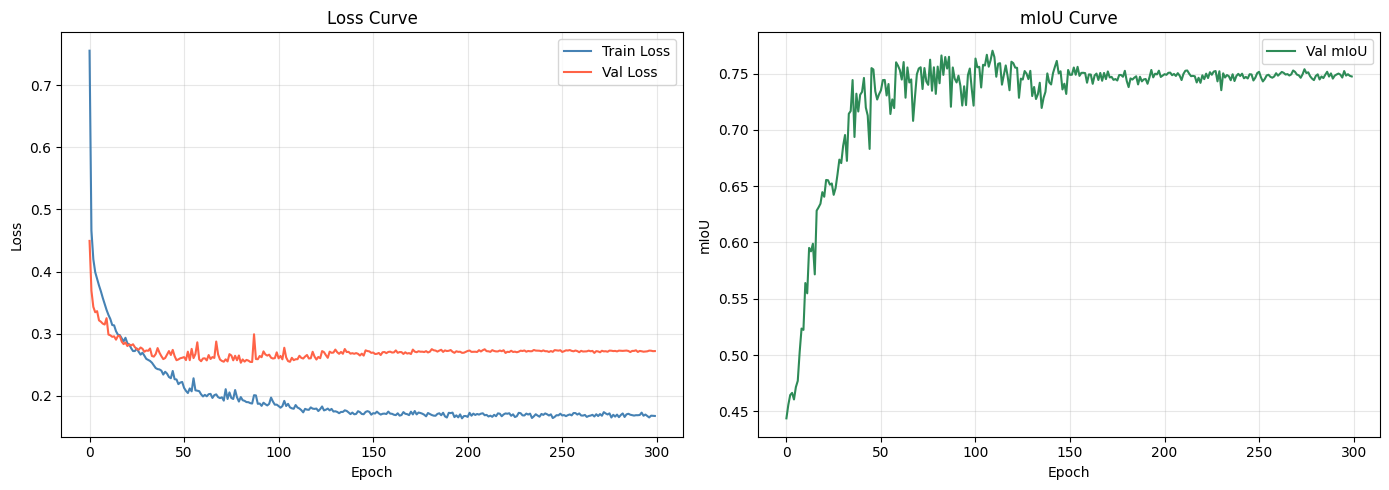

Learning curve disimpan.


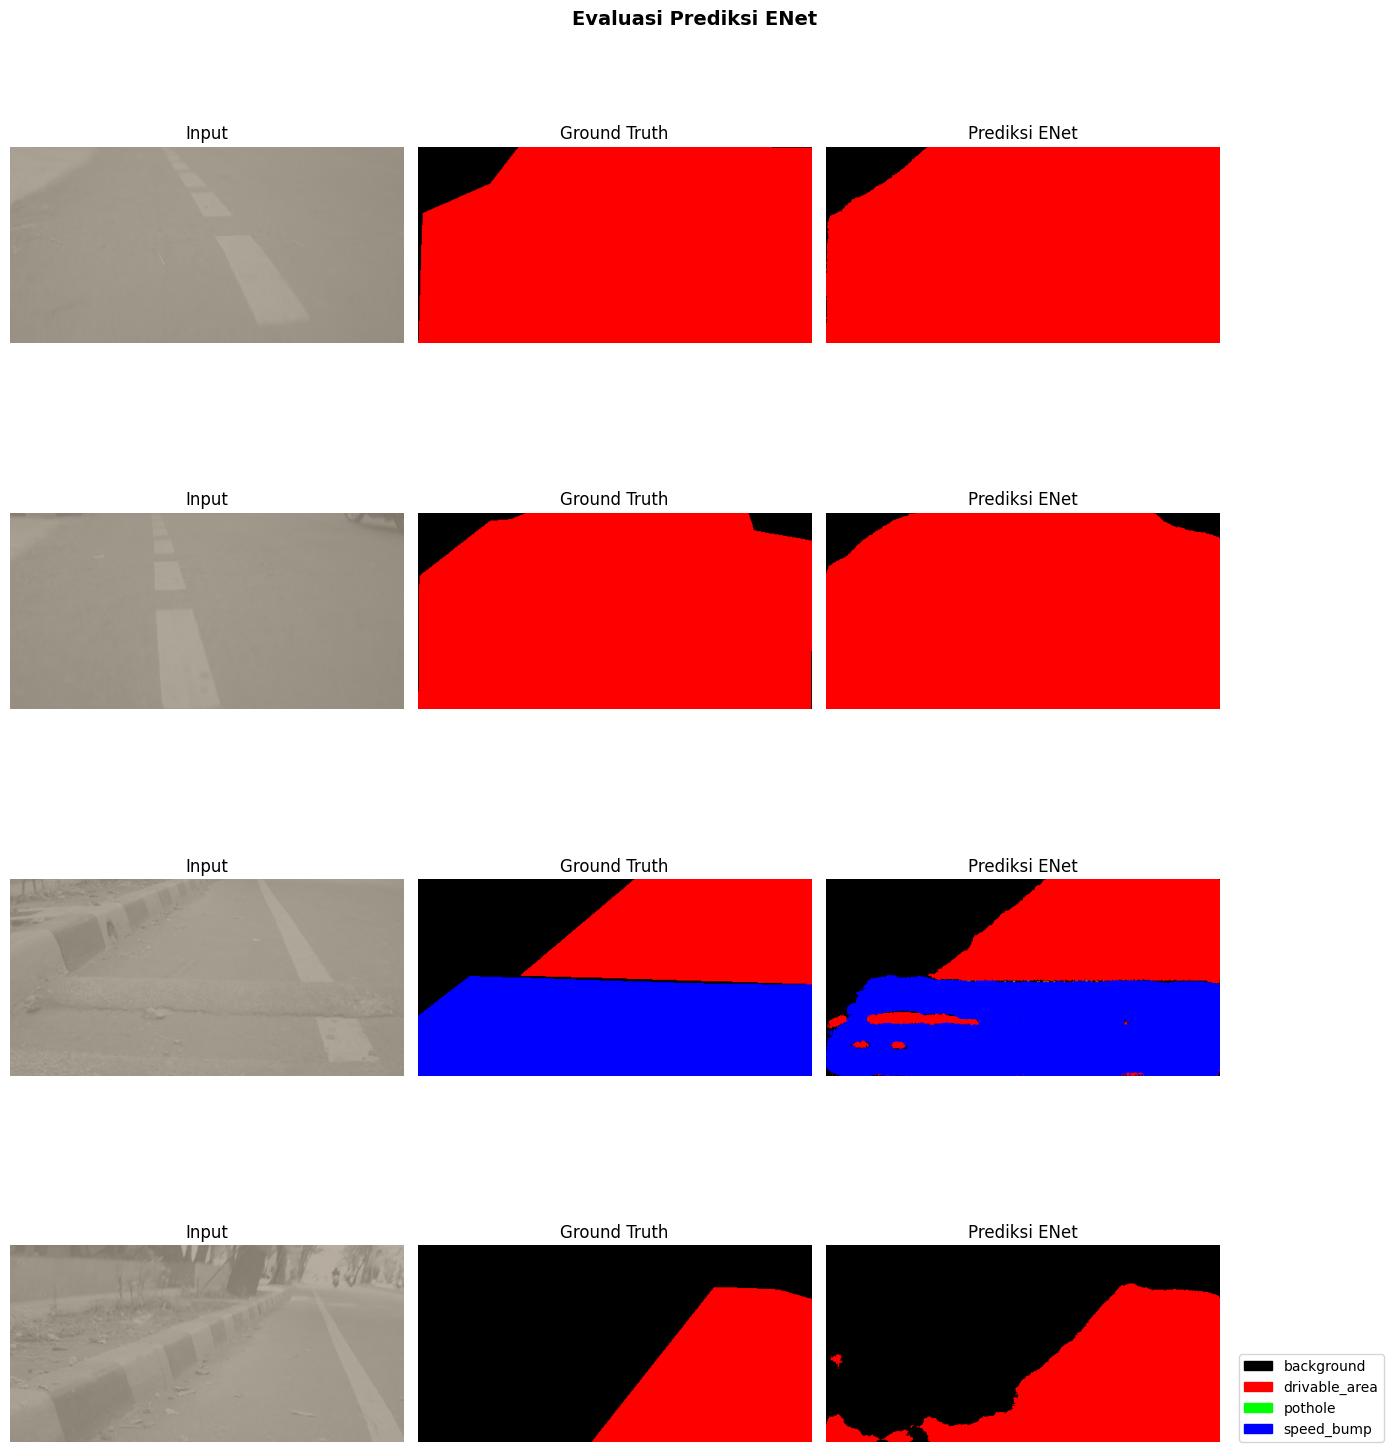

Visualisasi prediksi disimpan.

--- Per-Class IoU (Validation Set) ---
       background : IoU = 0.9324
    drivable_area : IoU = 0.9719
          pothole : IoU = 0.1640
       speed_bump : IoU = 0.5308
             mIoU : 0.6498


In [13]:
# ==========================================
# 8. EVALUASI & VISUALISASI HASIL
# ==========================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ---- Plot Learning Curve ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train Loss", color="steelblue")
axes[0].plot(history["val_loss"],   label="Val Loss",   color="tomato")
axes[0].set_title("Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["val_miou"], label="Val mIoU", color="seagreen")
axes[1].set_title("mIoU Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_OUTPUT_DIR, "learning_curve.png"), dpi=120)
plt.show()
print("Learning curve disimpan.")


# ---- Visualisasi Prediksi vs Ground Truth ----
# Palet warna untuk tiap kelas (tambah jika NUM_CLASSES > 5)
COLOR_PALETTE = [
    [0,   0,   0],    # background → hitam
    [255, 0,   0],    # class 1    → merah
    [0,   255, 0],    # class 2    → hijau
    [0,   0,   255],  # class 3    → biru
    [255, 255, 0],    # class 4    → kuning
]

def mask_to_rgb(mask_tensor):
    """Konversi mask class index ke gambar RGB berwarna."""
    h, w   = mask_tensor.shape
    rgb    = np.zeros((h, w, 3), dtype=np.uint8)
    for cls, color in enumerate(COLOR_PALETTE[:NUM_CLASSES]):
        rgb[mask_tensor == cls] = color
    return rgb

def denormalize(tensor):
    """Kembalikan tensor yang sudah dinormalisasi ke rentang [0, 1]."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (tensor * std + mean).clamp(0, 1)

# Load best model untuk evaluasi
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

N_VIS = 4  # jumlah sampel yang divisualisasikan
val_iter = iter(val_loader)
vis_images, vis_masks = next(val_iter)

fig, axes = plt.subplots(N_VIS, 3, figsize=(14, N_VIS * 4))
fig.suptitle("Evaluasi Prediksi ENet", fontsize=14, fontweight='bold')

with torch.no_grad():
    vis_preds = model(vis_images.to(device)).argmax(dim=1).cpu()

for i in range(min(N_VIS, len(vis_images))):
    img_disp  = denormalize(vis_images[i]).permute(1, 2, 0).numpy()
    mask_disp = mask_to_rgb(vis_masks[i].numpy())
    pred_disp = mask_to_rgb(vis_preds[i].numpy())

    axes[i][0].imshow(img_disp)
    axes[i][0].set_title("Input")
    axes[i][0].axis('off')

    axes[i][1].imshow(mask_disp)
    axes[i][1].set_title("Ground Truth")
    axes[i][1].axis('off')

    axes[i][2].imshow(pred_disp)
    axes[i][2].set_title("Prediksi ENet")
    axes[i][2].axis('off')

# Legend kelas
patches = [
    mpatches.Patch(color=[c/255 for c in COLOR_PALETTE[c]], label=CLASS_NAMES[c])
    for c in range(min(NUM_CLASSES, len(COLOR_PALETTE)))
]
plt.legend(handles=patches, bbox_to_anchor=(1.05, 0), loc='lower left', borderaxespad=0.)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_OUTPUT_DIR, "predictions_visualization.png"), dpi=120, bbox_inches='tight')
plt.show()
print("Visualisasi prediksi disimpan.")


# ---- Per-Class IoU Report ----
print("\n--- Per-Class IoU (Validation Set) ---")
class_iou = np.zeros(NUM_CLASSES)
class_cnt = np.zeros(NUM_CLASSES)

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        preds  = model(images).argmax(dim=1).cpu().numpy()
        masks  = masks.numpy()
        for c in range(NUM_CLASSES):
            pred_c = (preds == c)
            true_c = (masks == c)
            inter  = (pred_c & true_c).sum()
            union  = (pred_c | true_c).sum()
            if union > 0:
                class_iou[c] += inter / union
                class_cnt[c] += 1

for c in range(NUM_CLASSES):
    iou_c = class_iou[c] / class_cnt[c] if class_cnt[c] > 0 else float('nan')
    print(f"  {CLASS_NAMES[c]:>15s} : IoU = {iou_c:.4f}")
print(f"  {'mIoU':>15s} : {np.nanmean(class_iou / np.maximum(class_cnt, 1)):.4f}")

In [14]:
# ==========================================
# 9. ZIP & EXPORT MODEL
# ==========================================
# File yang akan tersedia di Output panel Kaggle:
# - Final_ENet_Model.zip  (berisi best_model.pth, checkpoint, learning curve, prediksi)

print("\n--- Menyiapkan Export ---")

# Simpan juga config model supaya mudah di-load ulang
import json
config = {
    "architecture"  : "ENet",
    "num_classes"   : NUM_CLASSES,
    "class_names"   : CLASS_NAMES,
    "img_height"    : IMG_HEIGHT,
    "img_width"     : IMG_WIDTH,
    "best_miou"     : round(best_miou, 4),
    "num_epochs"    : NUM_EPOCHS,
    "learning_rate" : LEARNING_RATE,
    "batch_size"    : BATCH_SIZE,
    "normalization" : {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
}
with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("config.json disimpan.")

# Zip seluruh direktori model
print("Membuat archive ZIP...")
shutil.make_archive("/kaggle/working/Final_ENet_Model", 'zip', MODEL_OUTPUT_DIR)
print("\n✅ Selesai! File tersedia di Output panel Kaggle:")
print("   📦 /kaggle/working/Final_ENet_Model.zip")
print(f"      └── best_model.pth          (Best mIoU: {best_miou:.4f})")
print("      └── checkpoint_epoch*.pth   (Checkpoints berkala)")
print("      └── learning_curve.png")
print("      └── predictions_visualization.png")
print("      └── config.json")


--- Menyiapkan Export ---
config.json disimpan.
Membuat archive ZIP...

✅ Selesai! File tersedia di Output panel Kaggle:
   📦 /kaggle/working/Final_ENet_Model.zip
      └── best_model.pth          (Best mIoU: 0.7705)
      └── checkpoint_epoch*.pth   (Checkpoints berkala)
      └── learning_curve.png
      └── predictions_visualization.png
      └── config.json
